**Combine `IIVV-analysis_{class_task}_gpu.csv`**

In [1]:
from glob import glob
import pandas as pd

In [10]:
files = glob("results/IIVV-analysis_*_gpu.csv")
# results/IIVV-analysis_{class_task}_IIVVALL_gpu.csv
# f"results/IIVV-analysis_{class_task}_gpu.csv"
print(files)
dfs = [pd.read_csv(f) for f in files]
combined = pd.concat(dfs, ignore_index=True)
combined.to_csv("results/IIVV-analysis-all.csv", index=False)

['results/IIVV-analysis_healthy_vs_cancer_gpu.csv', 'results/IIVV-analysis_hr_vs_lr_gpu.csv', 'results/IIVV-analysis_MC_gpu.csv', 'results/IIVV-analysis_healthy_vs_cancer_IIVVALL_gpu.csv', 'results/IIVV-analysis_hr_vs_lr_IIVVALL_gpu.csv', 'results/IIVV-analysis_MC_IIVVALL_gpu.csv']


In [7]:
files = glob("results/IIVV-analysis_M*_gpu.csv")
dfs = [pd.read_csv(f) for f in files]

In [6]:
combined = pd.concat(dfs, ignore_index=True)

In [8]:
combined.to_csv(f"results/IIVV-analysis_MC_gpu.csv", index=False)

___

In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    auc,
)
from toolbox import (
    Masking,
    compute_ROC_patient_split,
    find_all_indices,
    hot_coding,
)
from toolbox.loading import load_data, load_data_no_norm
from toolbox.visualization import cmap_gradient

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

# set prints off
mask.prints = True

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_hr_vs_lr,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"hr_vs_lr"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
class_task = "hr_vs_lr"
# class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "hr_vs_lr":
    print("\nHigh risk vs. low risk\n")
    select_idx = find_all_indices(
        labels_hr_vs_lr, ["High risk", "Low risk"], split=False
    )
    labels = labels_hr_vs_lr[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)


High risk vs. low risk

High risk: 125 entries
Low risk: 41 entries
Available cases: ['High risk' 'Low risk']
Coding: -> forward
{'High risk': [1, 0], 'Low risk': [0, 1]}

Inverse mapping: {(1, 0): 'High risk', (0, 1): 'Low risk'}
(166, 31, 7728) (166, 2) (166,)


## Analysis stage: IIVV selection (only)

In [6]:
# load masking selection
Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

In [7]:
print(len(Mask_sel))

13


In [8]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

All 	 all
Long a+ 	 vv_long_across
Long a+ ext. 	 vv_long_across_extended
Med. a+ ext. 	 vv_medium_across_extended
Skip1 close 	 vv_distance_close_skip_1
Adj. close 	 adjacent_close
Med. adj. 	 vv_distance_medium_adj
Adj. far 	 adjacent_far
Skip1 medium 	 skip1_medium
Skip1 far 	 skip1_far
Opp. close 	 opposite_close
Opp. medium 	 opposite_medium
Opp. far 	 opposite_far


Develop new IIVV pattern set from an impedance threshold based on noise floor of data 
Goal would be to filter out patterns that are below that floor 

In [9]:
# Load impedance data, no norm
(py_idx, patient_no, patient_sample, Zdata_abs, Avg_Cutpats) = load_data_no_norm(
    path="data", Cutpats_threshold=60
)

X_raw = Zdata_abs[select_idx, ...]


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


In [10]:
# want to look at average impedance at each frequency for each sample
avg_Z_fp = np.mean(X_raw, axis=0)
avg_Z_sp = np.mean(X_raw, axis=1)
avg_Z_sf = np.mean(X_raw, axis=2)

std_Z_sf = np.std(X_raw, axis=2)
print("SNR all patterns and samples at each frequency")
print(np.mean(avg_Z_sf / std_Z_sf, axis=0))

print("Average impedance at each frequency")
print(np.mean(avg_Z_sf, axis=0))

# SNR of each pattern
std_Z_p = np.std(avg_Z_sp, axis=0)
avg_Z_p = np.mean(avg_Z_sp, axis=0)
print("Zeros in std_Z_p:", np.sum(std_Z_p == 0))
epsilon = 1e-10
iivv_snr = avg_Z_p / (std_Z_p + epsilon)

# plt.figure
# plt.plot(iivv_snr)

# 100 Hz has the lowest SNR surprisingly so that's what we'll use

SNR all patterns and samples at each frequency
[1.01612014 1.01692798 1.01746191 1.01832483 1.01946092 1.02081255
 1.02229593 1.02468453 1.02220271 1.02760214 1.02980341 1.02971836
 1.03262565 1.0379303  1.03987547 1.04418658 1.05024803 1.05614992
 1.0614325  1.06926396 1.07710357 1.08664968 1.09618404 1.10626068
 1.11748694 1.12807344 1.13902756 1.14976173 1.15941231 1.16917358
 1.1784623 ]
Average impedance at each frequency
[710.89771574 682.92670401 663.18400265 642.37523502 619.63519052
 594.97503438 568.28143885 535.78618865 511.38436969 481.82019395
 448.58135137 414.05077052 389.03965696 352.74806758 332.37391001
 304.89929472 278.06482979 254.96133779 235.96961834 215.40420496
 198.51700361 183.12170175 169.43735068 157.21794714 146.04943729
 136.00335951 126.70031026 118.15834317 110.070562   102.33427304
  95.04511254]
Zeros in std_Z_p: 48


In [11]:
Mask_sel.keys()

dict_keys(['All', 'Long a+', 'Long a+ ext.', 'Med. a+ ext.', 'Skip1 close', 'Adj. close', 'Med. adj.', 'Adj. far', 'Skip1 medium', 'Skip1 far', 'Opp. close', 'Opp. medium', 'Opp. far'])

config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])
Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
config: vv_long_across_extended={'26_31': [1, 2, 3, 21, 22, 23], '27_30': [3, 4, 5, 23, 24, 25], '28_33': [1, 5, 6, 10, 11, 15], '29_32': [11, 15, 16, 20, 21, 25], '30_26': [1, 2, 3, 23, 24, 25], '31_27': [3, 4, 5, 21, 22, 23], '32_28': [5, 10, 11, 15, 16, 21], '33_29': [1, 6, 11, 15, 20, 25]}
Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
config: vv_medium_across_extended={'26_31': [6, 7, 8, 16, 17, 18], '27_30': [8, 9, 10, 18, 19, 20], '28_33': [2, 4, 7, 9, 12, 14], '29_32': [12,

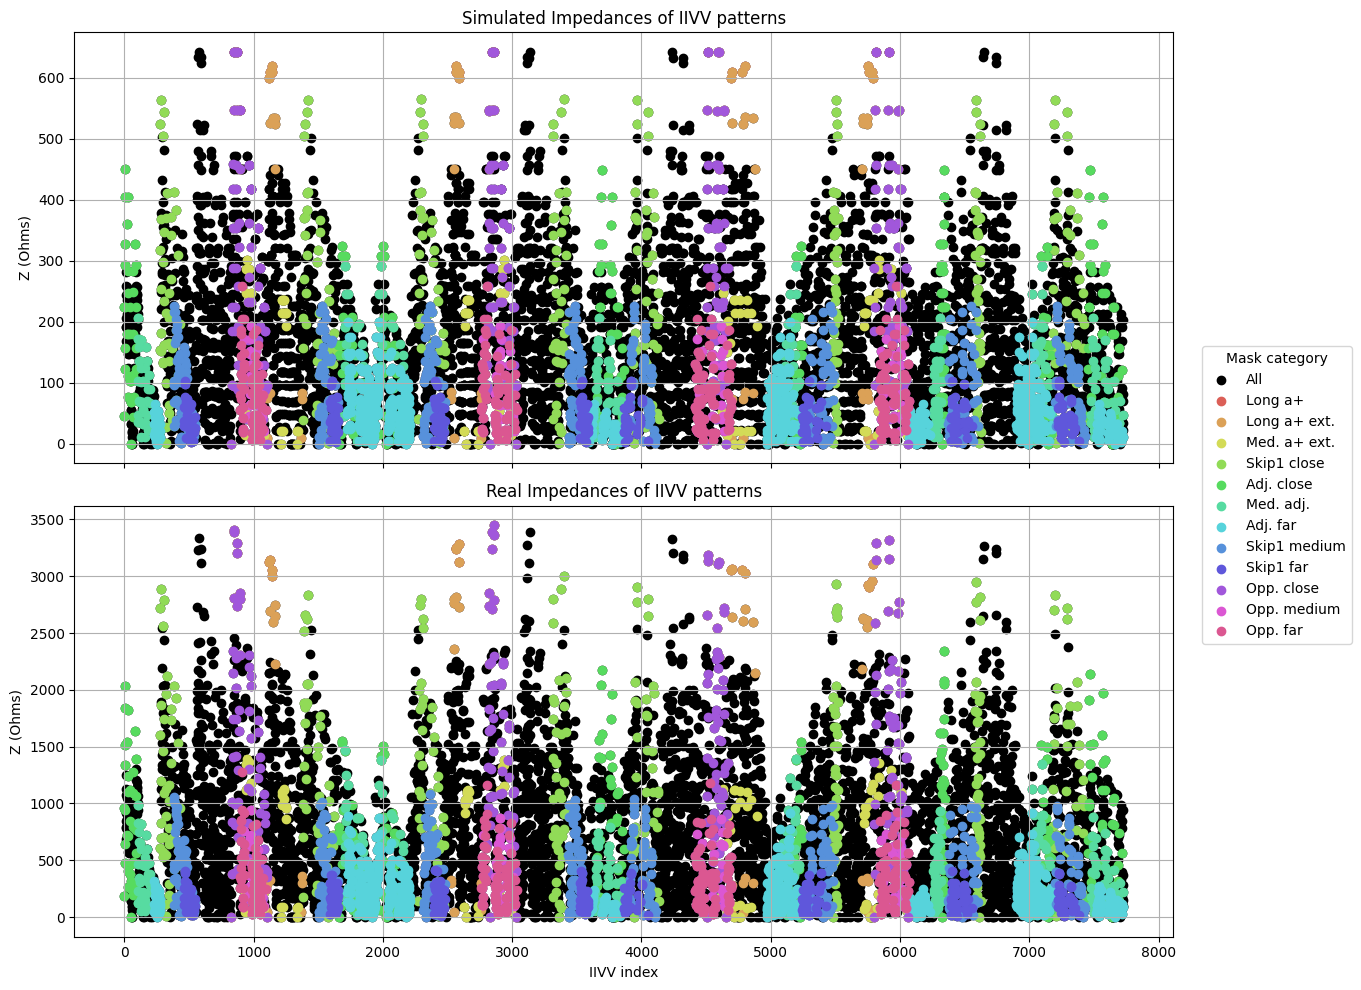

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
Zsim = pd.read_csv("source/Zsim.csv", header=None).squeeze()  # squeeze to Series
Zsim = np.abs(Zsim)
iivv_set = np.arange(len(Zsim))  # indices for each data point

# Assume Mask_sel is a dictionary, keys are mask names, values are masks or "all"
# Assume mask.IIVV_mask(Msel, plot=False) sets mask.mask boolean array for selection

# Set up color palette
categories = list(Mask_sel.keys())
base_palette_seeds = sns.color_palette("hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = (0, 0, 0)  # black for "All"
    else:
        palette[cat] = base_palette_seeds[i]
        i += 1

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(12, 10), sharex=True)

# Plotting simulated data
axs[0].set_title("Simulated Impedances of IIVV patterns")
axs[0].set_ylabel("Z (Ohms)")
axs[0].grid(True)

plotted_labels = set()  # To avoid duplicate legend entries

# Plotting real data
axs[1].set_title("Real Impedances of IIVV patterns")
axs[1].set_xlabel("IIVV index")
axs[1].set_ylabel("Z (Ohms)")
axs[1].grid(True)


# To avoid duplicate legend entries, keep track of plotted labels
plotted_labels = set()

for Mname, Msel in Mask_sel.items():
    if Msel == "all":
        Zs_sim = Zsim.values
        iivv_plot = iivv_set

        # Real data
        Zs_real = avg_Z_fp[0, :]
    else:
        mask.IIVV_mask(Msel, plot=False)  # presumably sets mask.mask
        Zs_sim = Zsim.values[mask.mask]
        iivv_plot = iivv_set[mask.mask]

        # Real data
        Zs_real = avg_Z_fp[0, mask.mask]

    color = palette.get(Mname, (0.5, 0.5, 0.5))  # fallback grey

    if Mname not in plotted_labels:
        label = Mname
        plotted_labels.add(Mname)
    else:
        label = None

    axs[0].scatter(iivv_plot, Zs_sim, color=color, label=label)
    axs[1].scatter(iivv_plot, Zs_real, color=color, label=None)

# Adjust subplot to make space on the right for the legend
plt.subplots_adjust(right=0.8)  # leave 20% space on the right

# Single legend on the right, centered vertically
fig.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), ncol=1, title="Mask category")

plt.tight_layout()
plt.show()

config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])
Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
config: vv_long_across_extended={'26_31': [1, 2, 3, 21, 22, 23], '27_30': [3, 4, 5, 23, 24, 25], '28_33': [1, 5, 6, 10, 11, 15], '29_32': [11, 15, 16, 20, 21, 25], '30_26': [1, 2, 3, 23, 24, 25], '31_27': [3, 4, 5, 21, 22, 23], '32_28': [5, 10, 11, 15, 16, 21], '33_29': [1, 6, 11, 15, 20, 25]}
Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
config: vv_medium_across_extended={'26_31': [6, 7, 8, 16, 17, 18], '27_30': [8, 9, 10, 18, 19, 20], '28_33': [2, 4, 7, 9, 12, 14], '29_32': [12,

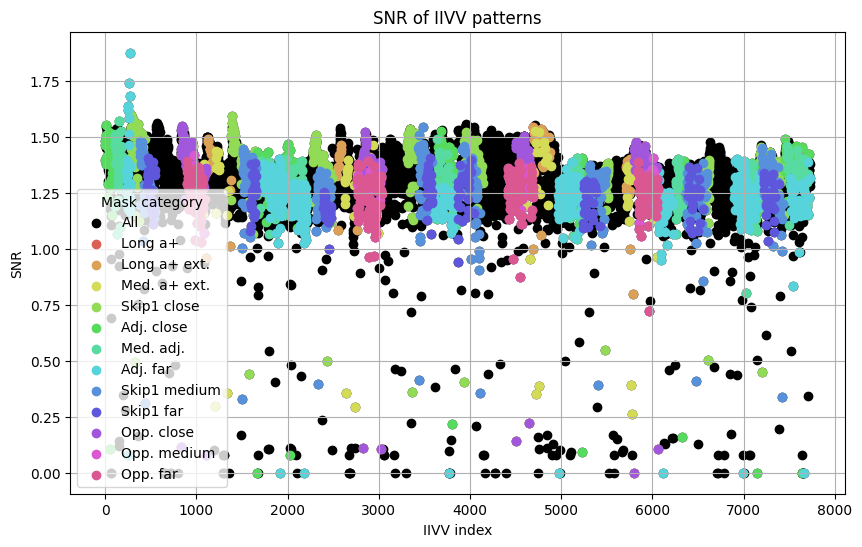

In [13]:
# Plot iivv set SNR

plt.figure(figsize=(10, 6))
plt.title("SNR of IIVV patterns")
plt.xlabel("IIVV index")
plt.ylabel("SNR")
plt.grid(True)

plotted_labels = set()

for Mname, Msel in Mask_sel.items():
    if Msel == "all":
        Z_snr = iivv_snr
        iivv_plot = iivv_set

    else:
        mask.IIVV_mask(Msel, plot=False)  # presumably sets mask.mask
        Z_snr = iivv_snr[mask.mask]
        iivv_plot = iivv_set[mask.mask]

    color = palette.get(Mname, (0.5, 0.5, 0.5))  # fallback grey

    # Only add label once per category in legend
    label = Mname if Mname not in plotted_labels else None
    plt.scatter(iivv_plot, Z_snr, color=color, label=label)
    plotted_labels.add(Mname)


plt.legend(title="Mask category")
plt.show()

# Testing z threshold to find impedance ranges that improve AUCs

In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import label_binarize
from sklearn.svm import SVC
from toolbox.results import Results_data_loading
from tqdm import tqdm

In [15]:
min_z = 1
max_z = np.max(avg_Z_fp[0, :])
print(f"Max z threshold: {max_z}")
z_thresholds = np.linspace(min_z, max_z, num=100)
n_trials = 5
n_splits = 5

if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "hr_vs_lr":
    print("\nHigh risk vs low risk\n")
    select_idx = find_all_indices(
        labels_hr_vs_lr, ["High risk", "Low risk"], split=False
    )
    labels = labels_hr_vs_lr[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X_task = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

Y_labels = np.argmax(Y, axis=1)
classes = np.unique(Y_labels)
n_classes = len(classes)

import cupy as cp
import cudf
from cuml.svm import SVC
from cuml.metrics import roc_auc_score as cuml_roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import label_binarize
from tqdm import tqdm
import numpy as np
import pandas as pd

stats = []
trial_idx = 1

for rs in tqdm(range(n_trials)):
    # GPU SVC
    m = SVC(probability=True, random_state=0)
    cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)

    for z_thresh in z_thresholds:
        above_threshold = avg_Z_fp[0, :] <= z_thresh
        num_iivv = np.sum(above_threshold)

        # Slice and reshape data
        X_thresholded = X_task[:, :, above_threshold]
        X_tmp = X_thresholded.reshape(X_thresholded.shape[0], -1)

        aucs_per_fold = []

        for train_idx, test_idx in cv.split(X_tmp, Y, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

            # GPU arrays (transfer to device)
            X_train_gpu = cp.asarray(X_train)
            X_test_gpu = cp.asarray(X_test)
            y_train_gpu = cp.asarray(y_train)

            m.fit(X_train_gpu, y_train_gpu)

            probs_gpu = m.predict_proba(X_test_gpu)
            probs = cp.asnumpy(probs_gpu)

            if n_classes == 2:
                roc_auc = float(
                    cuml_roc_auc_score(cp.asarray(y_test), cp.asarray(probs[:, 1]))
                )
            else:
                y_bin = label_binarize(y_test, classes=classes)
                y_bin_gpu = cp.asarray(y_bin)
                roc_auc = float(
                    cuml_roc_auc_score(y_bin_gpu.ravel(), cp.asarray(probs).ravel())
                )

            aucs_per_fold.append(roc_auc)

        mean_auc_trial = np.mean(aucs_per_fold)
        print(
            f"Threshold {z_thresh}, num iivvs: {num_iivv}, trial {trial_idx}, mean auc: {mean_auc_trial}"
        )

        stats.append(
            {
                "Task": class_task,
                "z_threshold": z_thresh,
                "IIVV": num_iivv,
                "rs": rs,
                "auc": mean_auc_trial,
            }
        )

    print(f"Trial {trial_idx} complete")
    trial_idx += 1

# DataFrame (GPU → CPU)
df_stats = cudf.DataFrame(stats).to_pandas()

csv_fname = f"results/IIVV-z_threshold_{min_z}_{max_z}_{class_task}.csv"
df_stats.to_csv(csv_fname, index=False)
print(f"Saved results to {csv_fname}")

Max z threshold: 3448.5080169998705

High risk vs low risk

High risk: 125 entries
Low risk: 41 entries
Available cases: ['High risk' 'Low risk']
Coding: -> forward
{'High risk': [1, 0], 'Low risk': [0, 1]}

Inverse mapping: {(1, 0): 'High risk', (0, 1): 'Low risk'}
(166, 31, 7728) (166, 2) (166,)


ImportError: /home/jt292/miniconda3/envs/TF2_19/bin/../lib/libcusparse.so.12: undefined symbol: __nvJitLinkGetErrorLogSize_12_9, version libnvJitLink.so.12

In [16]:
# Load in results
# Load data
# df_stats = pd.read_csv("results/cancer_vs_hbd_0_3811_healthy_vs_cancer.csv")
df_stats

# number of iivv patterns in best performing one
# filtered_df = df_stats[df_stats['z_threshold'] == 384.95261399498247]
# filtered_df['IIVV']

NameError: name 'df_stats' is not defined

NameError: name 'df_stats' is not defined

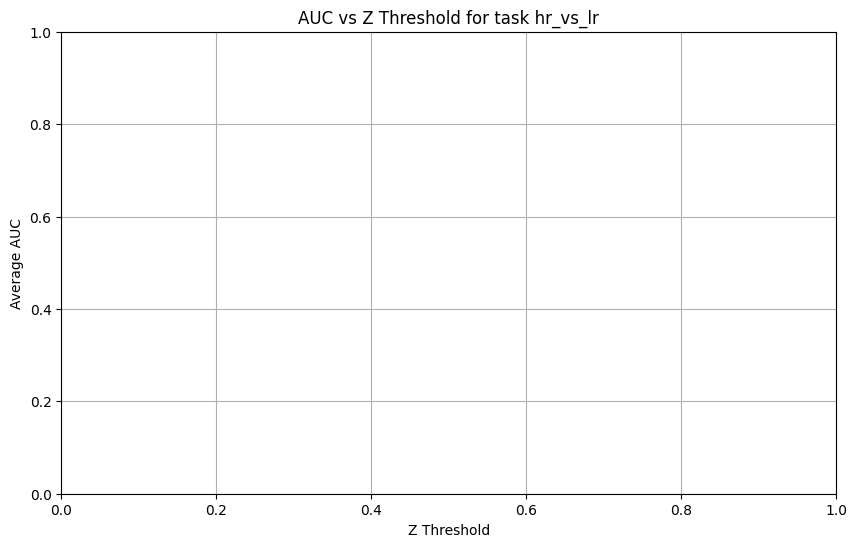

In [17]:
class_task = "hr_vs_lr"
# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.title(f"AUC vs Z Threshold for task {class_task}")
plt.xlabel("Z Threshold")
plt.ylabel("Average AUC")
plt.grid(True)


# Plot each trial's AUC as a line
# We pivot so that each column is a trial rs, index=z_threshold
aucs_pivot = df_stats.pivot(index="z_threshold", columns="rs", values="auc")

for trial_idx in aucs_pivot.columns:
    plt.plot(
        aucs_pivot.index,
        aucs_pivot[trial_idx],
        alpha=0.5,
        linestyle="--",
        marker="o",
        label=f"Trial {trial_idx + 1}",
    )

# Compute average AUC across trials for each threshold
mean_aucs_per_threshold = df_stats.groupby("z_threshold")["auc"].mean()
plt.plot(
    mean_aucs_per_threshold.index,
    mean_aucs_per_threshold.values,
    marker="x",
    color="steelblue",
    linewidth=2,
    label="Mean AUC (all trials)",
)
# plot the max auc of the mean
max_auc = mean_aucs_per_threshold.max()
idx_max = mean_aucs_per_threshold.idxmax()
print(f"Max AUC with z-threshold: {idx_max}")
plt.plot(idx_max, max_auc, marker="s", color="black", label="Max AUC")

plt.legend()
plt.tight_layout()

save_flg = True
if save_flg:
    plt.savefig(f"{class_task}_auc_vs_zthreshold.pdf", bbox_inches="tight")
    print(f"Plot saved to {class_task}_auc_vs_zthreshold.pdf")

plt.show()

In [17]:
results = []
numXparams = []
n_trials = 10

for Mname, Msel in Mask_sel.items():
    if Msel == "all":
        X_tmp = X[:, :, :]
    else:
        # apply mask
        mask.IIVV_mask(Msel, plot=False)
        X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(n_trials):
        print("Trial:", trial, "\n\t", Mname)
        avg_roc_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})

df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/IIVV-analysis_{class_task}.csv", index=False)
df_params.to_csv(f"results/IIVV-analysis_{class_task}_params.csv", index=False)

Trial: 0 
	 All
Train patients: [48 29 46 27  6 45 51 77 92 81 88 91  3 69 89 30 19 57 58 86 66 62 44  4
 16 18 43 41  5 90 56  0 37 31 53 12 38 25 55 11 34 74 60 78  1 35 85 15
 71 20 32 52 97 98 72 21 93 75 80 28 40 49 42 68 61 13 73 39 22 87  9 95
 70 67 50 47]
Test patients: [ 2 33 59 17 14 64 65 83 36 82 79  7 54 94 99 63  8 24 76]
Trial: 1 
	 All
Train patients: [41 56 76 20 93 99 38 36 51 73 69 57 39 48 55 25 37 85 59 97 16 81 44 90
 29 98 46 62  4 68 22 86  3 72 33 65 45 50 54 87 27  8 18 63  0 89 60 24
 64 66  7 95 14 71 83 15 32 31 12 19 21 53 28  6 74 79  1 17 67 82  5 78
  9 75 13 40]
Test patients: [43 34 49 61 80 52 91 47 92 94 70 30 77 88 35 58 42 11  2]
Trial: 2 
	 All
Train patients: [69 12 83 33 32  5 97 59 99 93  1 19 27 47 38 63  6 51 90 11 13 77 68 94
 35 20 65 74 56  9 95 18 60 58 44 64 48 67  8 73 81 89 98 29 79 53 55 85
 49 71 72 80 61 36 41 54 45  4 70 42 40 21 34 66 50 92 52 37  7 78 86 46
 24 75 16 43]
Test patients: [39 31 57 25 17 82  2 28 87 14 62 91 88 15

In [1]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

NameError: name 'pd' is not defined

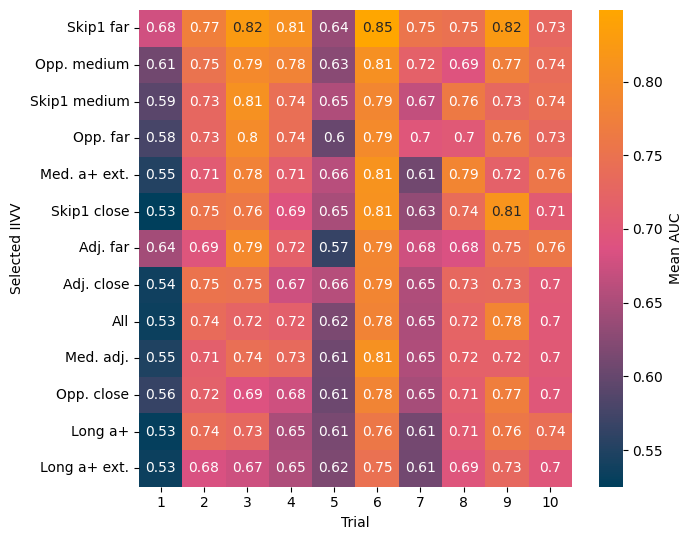

In [20]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)
# save
np.savez(
    f"results/Top_IIVV_masks_{class_task}.npz",
    maskmeans_order=mask_means[order],
    Mask_ranks=mask_means[order].keys(),
)
fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "Mean AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [21]:
df_pivot

Trial,1,2,3,4,5,6,7,8,9,10
Mask,,,,,,,,,,
Skip1 far,0.677929,0.774183,0.824757,0.805716,0.635492,0.848505,0.753265,0.748370,0.824172,0.727857
Opp. medium,0.608266,0.750397,0.793908,0.781405,0.625496,0.806387,0.717916,0.691116,0.772895,0.738525
Skip1 medium,0.590960,0.728548,0.807511,0.743581,0.653424,0.786919,0.666999,0.763874,0.730561,0.744337
Opp. far,0.577584,0.726190,0.796595,0.741850,0.601386,0.794639,0.696019,0.700793,0.759126,0.729893
Med. a+ ext.,0.550909,0.705159,0.780063,0.713269,0.660068,0.810993,0.607428,0.786454,0.718020,0.756681
Skip1 close,0.525194,0.752965,0.760528,0.691779,0.648434,0.809477,0.631929,0.738313,0.814358,0.706924
Adj. far,0.644099,0.693814,0.793379,0.717850,0.565506,0.787335,0.675717,0.684713,0.747283,0.757643
Adj. close,0.537391,0.752521,0.749835,0.674680,0.658850,0.785611,0.653168,0.730307,0.732225,0.701981
All,0.534318,0.736461,0.723024,0.715589,0.615200,0.782810,0.651470,0.723376,0.784884,0.699544


In [22]:
print("Ranked by best preformance")
print(mask_means[order])

Ranked by best preformance
Mask
Skip1 far       0.762025
Opp. medium     0.728631
Skip1 medium    0.721671
Opp. far        0.712408
Med. a+ ext.    0.708904
Skip1 close     0.707990
Adj. far        0.706734
Adj. close      0.697657
All             0.696668
Med. adj.       0.694568
Opp. close      0.686358
Long a+         0.684119
Long a+ ext.    0.663997
dtype: float64


In [23]:
df_plot

,Mask,n_params,avg. ROC AUC
0,All,239568,0.696668
1,Long a+,496,0.684119
2,Long a+ ext.,3720,0.663997
3,Med. a+ ext.,3720,0.708904
4,Skip1 close,11160,0.707990
5,Adj. close,9052,0.697657
6,Med. adj.,11997,0.694568
7,Adj. far,20460,0.706734
8,Skip1 medium,13640,0.721671
9,Skip1 far,6944,0.762025


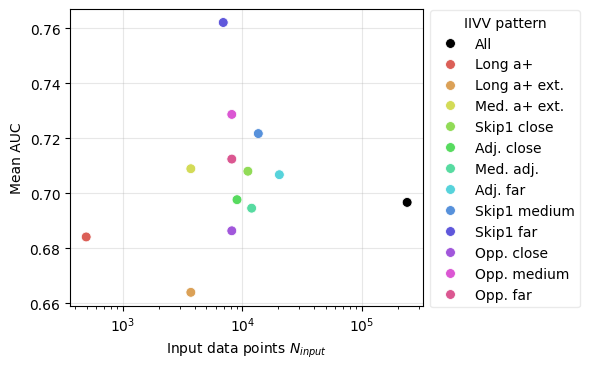

In [24]:
categories = df_plot["Mask"].unique()
base_palette = sns.color_palette(palette="hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = "black"
    else:
        palette[cat] = base_palette[i]
        i += 1

fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    palette=palette,
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Input data points $N_{input}$")
ax1.set_ylabel("Mean AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Take heuristically selected IIVV pattern

In [25]:
# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}

In [26]:
# add baseline pattern
Mask_sel["All"] = "all"

In [27]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

Skip1 medium 	 skip1_medium
Skip1 far 	 skip1_far
Opp. medium 	 opposite_medium
Opp. far 	 opposite_far
All 	 all


In [ ]:
results = []
numXparams = []
for Mname, Msel in Mask_sel.items():
    mask.IIVV_mask(Msel, plot=False)
    # apply mask
    X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(7):
        print("Trial:", trial, "\n\t", Mname)
        avg_roc_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})

df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/IIVV-analysis_{class_task}_sm.csv", index=False)
df_params.to_csv(f"results/IIVV-analysis_{class_task}_params_sm.csv", index=False)

ii_pattern=[[26, 28], [27, 29], [28, 30], [29, 31], [30, 32], [31, 33], [32, 26], [33, 27]]
config: vv_distance_medium_skip_1={'26_28': [6, 7, 8, 9, 11, 12, 13, 14, 18, 19, 23, 24], '27_29': [6, 7, 8, 9, 11, 12, 13, 14, 18, 19, 23, 24], '28_30': [3, 4, 8, 9, 11, 12, 13, 14, 16, 17, 18, 19], '29_31': [3, 4, 8, 9, 11, 12, 13, 14, 16, 17, 18, 19], '30_32': [2, 3, 7, 8, 12, 13, 14, 15, 17, 18, 19, 20], '31_33': [2, 3, 7, 8, 12, 13, 14, 15, 17, 18, 19, 20], '32_26': [7, 8, 9, 10, 12, 13, 14, 15, 17, 18, 22, 23], '33_27': [7, 8, 9, 10, 12, 13, 14, 15, 17, 18, 22, 23]}
Mask set by IIVV pattern rule.
True: 440 (5.69%)	False: 7288(94.31%)
Trial: 0 
	 Skip1 medium
Train patients: [48 29 46 27  6 45 51 77 92 81 88 91  3 69 89 30 19 57 58 86 66 62 44  4
 16 18 43 41  5 90 56  0 37 31 53 12 38 25 55 11 34 74 60 78  1 35 85 15
 71 20 32 52 97 98 72 21 93 75 80 28 40 49 42 68 61 13 73 39 22 87  9 95
 70 67 50 47]
Test patients: [ 2 33 59 17 14 64 65 83 36 82 79  7 54 94 99 63  8 24 76]
Trial: 1 
	 Sk

In [ ]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}_sm.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params_sm.csv")

In [ ]:
Mask_sel.keys()

In [ ]:
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

fig = plt.figure(figsize=(9.4, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
# defined order
# order = [
#    "Skip1 medium",
#    "Skip1 far",
#    "Opp. medium",
#    "Long a+",
#    "All",
# ]
order = Mask_sel.keys()
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Mask"],
        markersize=8,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.set_xscale("log")
# ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

ax1.legend(title="IIVV selection", framealpha=0.4)
plt.savefig(f"results/IIVV_sel_perf_{class_task}_sm.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_plot

___

## Statistical impact of IIVV maskimport numpy as np

cancer_vs_lr_hr

	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. LR vs. HR

Cancer: 96 entries
High risk: 29 entries
Low risk: 41 entries
Available cases: ['Cancer' 'High risk' 'Low risk']
Coding: -> forward
{'Cancer': [1, 0, 0], 'High risk': [0, 1, 0], 'Low risk': [0, 0, 1]}


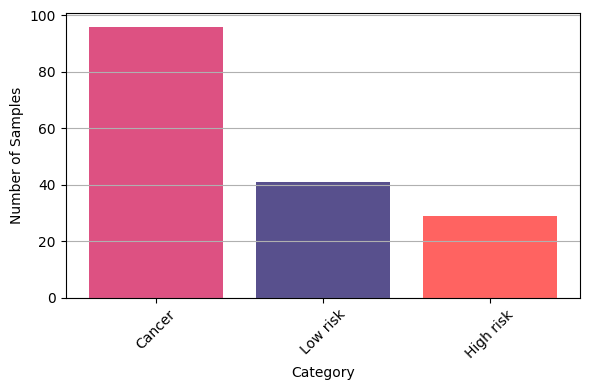


Inverse mapping: {(1, 0, 0): 'Cancer', (0, 1, 0): 'High risk', (0, 0, 1): 'Low risk'}
(166, 31, 7728) (166, 3) (166,)


  5%|███▎                                                               | 1/20 [01:21<25:45, 81.33s/it]


KeyboardInterrupt: 

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox.results import Results_data_loading
from tqdm import tqdm
from sklearn.preprocessing import label_binarize
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel

IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

tasks = ["hr_vs_lr"]


for class_task in tasks:
    stats = []
    print(class_task)
    X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
        class_task, data_augmentation=False
    )
    classes = np.unique(Y_labels)
    n_classes = len(classes)

    for Msel in Mask_sel.keys():
        if Msel == "All":
            X_tmp = X.reshape(X.shape[0], -1)
        else:
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            X_tmp = X[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
        for rs in tqdm(range(20)):
            m = SVC(probability=True, random_state=0)
            cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
            for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
                X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
                y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
                m.fit(X_train, y_train)
                probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
                if n_classes == 2:
                    roc_auc = roc_auc_score(y_test, probs[:, 1])
                else:
                    # Binarize true labels
                    y_bin = label_binarize(
                        y_test, classes=classes
                    )  # shape (n_samples, n_classes)
                    # Micro-average ROC
                    fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                    roc_auc = auc(fpr, tpr)
                stats.append(
                    {"Task": class_task, "IIVV": Msel, "rs": rs, "auc": roc_auc}
                )

    df_stats = pd.DataFrame(stats)
    df_stats.to_csv(f"results/IIVV-analysis_{class_task}_statistics.csv", index=False)

cancer_vs_lr_hr

	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. LR vs. HR

Cancer: 96 entries
High risk: 29 entries
Low risk: 41 entries
Available cases: ['Cancer' 'High risk' 'Low risk']
Coding: -> forward
{'Cancer': [1, 0, 0], 'High risk': [0, 1, 0], 'Low risk': [0, 0, 1]}


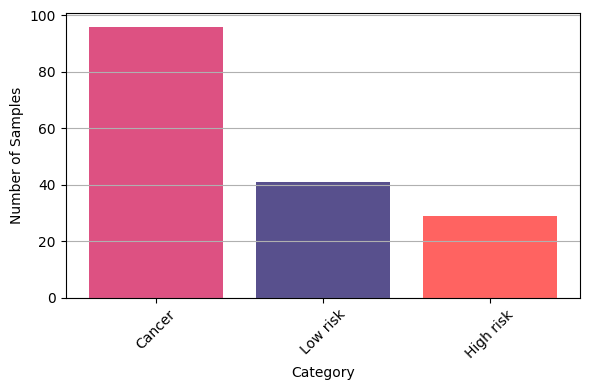


Inverse mapping: {(1, 0, 0): 'Cancer', (0, 1, 0): 'High risk', (0, 0, 1): 'Low risk'}
(166, 31, 7728) (166, 3) (166,)
Task 2 Z-threshold: 314


100%|██████████████████████████████████████████████████████████████████| 20/20 [09:51<00:00, 29.57s/it]


In [4]:
# Z threshold results
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox.results import Results_data_loading
from tqdm import tqdm
from sklearn.preprocessing import label_binarize
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel

IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
tasks = ["hr_vs_lr"]

# Z-thresholding selection
for class_task in tasks:
    stats = []
    print(class_task)
    X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
        class_task, data_augmentation=False
    )
    classes = np.unique(Y_labels)
    n_classes = len(classes)

    # load in average impedances
    avg_Z_fp = np.load("source/Avg_Zs.npy")

    if class_task == "healthy_vs_cancer":
        print("Task 1 Z-threshold: 386")
        z_thresh = 386
    elif class_task == "cancer_vs_hbd":
        print("Task 2 Z-threshold: 423")
        z_thresh = 423
    elif class_task == "hr_vs_lr":
        print("Task 2 Z-threshold: 314")
        z_thresh = 314
    elif class_task == "MC":
        print("Task 3 Z-threshold: 592")
        z_thresh = 592

    Msel = f"z_threshold: {z_thresh}"

    # Select columns/patterns for this threshold
    above_threshold = avg_Z_fp[0, :] <= z_thresh
    X_tmp = X[:, :, above_threshold]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
            if n_classes == 2:
                roc_auc = roc_auc_score(y_test, probs[:, 1])
            else:
                # Binarize true labels
                y_bin = label_binarize(
                    y_test, classes=classes
                )  # shape (n_samples, n_classes)
                # Micro-average ROC
                fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                roc_auc = auc(fpr, tpr)

            stats.append({"Task": class_task, "IIVV": Msel, "rs": rs, "auc": roc_auc})

    df_stats = pd.DataFrame(stats)
    df_stats.to_csv(
        f"results/IIVV-analysis_{class_task}_z_threshold_statistics.csv", index=False
    )